# Telco Customer Churn — End-to-End Logistic Regression

This notebook explores the supplied customer file, builds a churn-probability model, evaluates it on customers held out from training, and saves customer-level predictions. Run the cells from top to bottom. The holdout set is treated as unseen when the model makes its predictions; its known churn labels are used only afterward to measure performance.

**Dataset notes from the full-file review:** 7,043 customers and 21 columns; 5,174 stayed and 1,869 churned (26.5% churn). Eleven `TotalCharges` values are blank; each belongs to a zero-tenure customer. There are no duplicate rows or customer IDs. Contract churn rates differ substantially: month-to-month 42.7%, one-year 11.3%, and two-year 2.8%. These are descriptive associations, not proof of cause.

## 1. Import libraries

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
RANDOM_STATE = 42
print("Libraries loaded; reproducible random state:", RANDOM_STATE)

Libraries loaded; reproducible random state: 42


## 2. Load the dataset

In [2]:
DATA_PATH = Path("Telco-Customer-Churn.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH.resolve()}. Keep the CSV beside this notebook or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH.resolve()}")
print(f"Rows: {len(df):,} | columns: {len(df.columns)}")
display(df.head())

Loaded D:\Arja Manish_Logistic_Regression_Telco Customer Churn\Telco-Customer-Churn.csv
Rows: 7,043 | columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Understand the customer attributes

In [3]:
print("Shape:", df.shape)
print("\nColumns:")
for column in df.columns:
    print(f"- {column}: {df[column].nunique(dropna=False)} distinct values")
print("\nSummary of numeric fields:")
display(df.describe(include="number").T)

Shape: (7043, 21)

Columns:
- customerID: 7043 distinct values
- gender: 2 distinct values
- SeniorCitizen: 2 distinct values
- Partner: 2 distinct values
- Dependents: 2 distinct values
- tenure: 73 distinct values
- PhoneService: 2 distinct values
- MultipleLines: 3 distinct values
- InternetService: 3 distinct values
- OnlineSecurity: 3 distinct values
- OnlineBackup: 3 distinct values
- DeviceProtection: 3 distinct values
- TechSupport: 3 distinct values
- StreamingTV: 3 distinct values
- StreamingMovies: 3 distinct values
- Contract: 3 distinct values
- PaperlessBilling: 2 distinct values
- PaymentMethod: 4 distinct values
- MonthlyCharges: 1585 distinct values
- TotalCharges: 6531 distinct values
- Churn: 2 distinct values

Summary of numeric fields:


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


## 4. Check data types

In [4]:
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null_count": df.notna().sum()}))
print("TotalCharges is loaded as text and will be converted to numeric after inspecting blanks.")

,dtype,non_null_count
customerID,str,7043
gender,str,7043
SeniorCitizen,int64,7043
Partner,str,7043
Dependents,str,7043
tenure,int64,7043
PhoneService,str,7043
MultipleLines,str,7043
InternetService,str,7043
OnlineSecurity,str,7043


TotalCharges is loaded as text and will be converted to numeric after inspecting blanks.


## 5. Check missing and blank values

In [5]:
null_counts = df.isna().sum()
blank_counts = df.select_dtypes(include=["object", "string", "str"]).apply(
    lambda column: column.astype("string").str.strip().eq("").sum()
)
quality = pd.DataFrame({"null_values": null_counts, "blank_strings": blank_counts}).fillna(0).astype(int)
display(quality.loc[(quality != 0).any(axis=1)].sort_values(["null_values", "blank_strings"], ascending=False))
print(f"Null cells: {int(null_counts.sum())}; blank-string cells: {int(blank_counts.sum())}")
print("The blank TotalCharges entries are checked against tenure in the cleaning step below.")

,null_values,blank_strings
TotalCharges,0,11


Null cells: 0; blank-string cells: 11
The blank TotalCharges entries are checked against tenure in the cleaning step below.


## 6. Check duplicates

In [6]:
exact_duplicates = int(df.duplicated().sum())
duplicate_customer_ids = int(df["customerID"].duplicated().sum())
print(f"Exact duplicate rows: {exact_duplicates}")
print(f"Repeated customer IDs: {duplicate_customer_ids}")

Exact duplicate rows: 0
Repeated customer IDs: 0


## 7. Analyze the Churn target

,customers,share
Churn,,
No,5174,73.5%
Yes,1869,26.5%


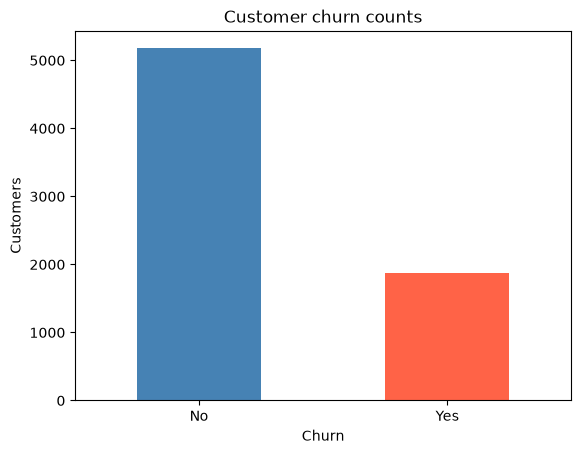

Baseline churn prevalence: 26.5%


In [7]:
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"], fill_value=0)
churn_rates = df["Churn"].value_counts(normalize=True).reindex(["No", "Yes"], fill_value=0)
display(pd.DataFrame({"customers": churn_counts, "share": churn_rates.map(lambda value: f"{value:.1%}")}))
ax = churn_counts.plot(kind="bar", color=["steelblue", "tomato"], rot=0, title="Customer churn counts")
ax.set_xlabel("Churn")
ax.set_ylabel("Customers")
plt.show()
print(f"Baseline churn prevalence: {churn_rates['Yes']:.1%}")

## 8. Explore churn patterns


Churn by Contract:


,customers,churn_rate
Contract,,
Month-to-month,3875,42.7%
One year,1473,11.3%
Two year,1695,2.8%



Churn by InternetService:


,customers,churn_rate
InternetService,,
DSL,2421,19.0%
Fiber optic,3096,41.9%
No,1526,7.4%



Churn by PaymentMethod:


,customers,churn_rate
PaymentMethod,,
Bank transfer (automatic),1544,16.7%
Credit card (automatic),1522,15.2%
Electronic check,2365,45.3%
Mailed check,1612,19.1%



Churn by tenure_band:


,customers,churn_rate
tenure_band,,
0-12,2186,47.4%
13-24,1024,28.7%
25-48,1594,20.4%
49-72,2239,9.5%


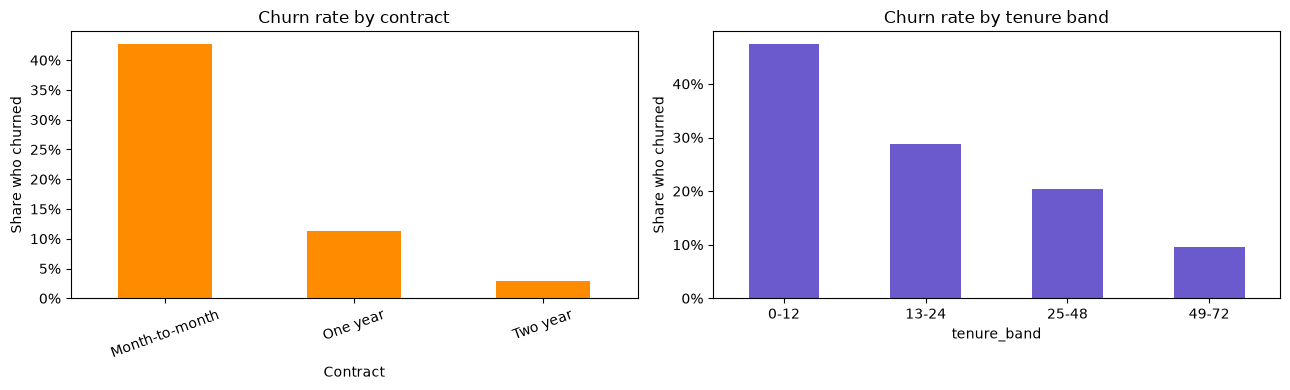

Observed group differences can guide investigation, but should not be interpreted as causal effects.


In [8]:
eda = df.copy()
eda["TotalCharges"] = pd.to_numeric(eda["TotalCharges"].astype("string").str.strip(), errors="coerce")
eda["tenure_band"] = pd.cut(
    eda["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"]
)
for feature in ["Contract", "InternetService", "PaymentMethod", "tenure_band"]:
    summary = eda.groupby(feature, observed=False)["Churn"].agg(
        customers="size", churn_rate=lambda values: values.eq("Yes").mean()
    )
    summary["churn_rate"] = summary["churn_rate"].map(lambda value: f"{value:.1%}")
    print(f"\nChurn by {feature}:")
    display(summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
contract_rate = eda.groupby("Contract", observed=False)["Churn"].apply(lambda values: values.eq("Yes").mean())
contract_rate.sort_values(ascending=False).plot(kind="bar", ax=axes[0], color="darkorange", rot=20)
axes[0].set_title("Churn rate by contract")
axes[0].set_ylabel("Share who churned")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
tenure_rate = eda.groupby("tenure_band", observed=False)["Churn"].apply(lambda values: values.eq("Yes").mean())
tenure_rate.plot(kind="bar", ax=axes[1], color="slateblue", rot=0)
axes[1].set_title("Churn rate by tenure band")
axes[1].set_ylabel("Share who churned")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
plt.tight_layout()
plt.show()
print("Observed group differences can guide investigation, but should not be interpreted as causal effects.")

## 9. Clean `TotalCharges`

Whitespace-only entries are converted to missing and then numeric. In this file all 11 such rows have tenure 0, so their accumulated charges are represented as 0. This is a domain-informed treatment of a new customer's accumulated total, not a general-purpose imputation rule.

In [9]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype("string").str.strip(), errors="coerce")
blank_total_charges = int(df["TotalCharges"].isna().sum())
blank_total_tenures = df.loc[df["TotalCharges"].isna(), "tenure"].value_counts().to_dict()
print(f"TotalCharges values requiring treatment: {blank_total_charges}")
print("Tenure counts among those rows:", blank_total_tenures)
if df.loc[df["TotalCharges"].isna(), "tenure"].ne(0).any():
    raise ValueError("Found a blank TotalCharges value for a customer with nonzero tenure; inspect before imputing.")
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Remaining missing TotalCharges:", int(df["TotalCharges"].isna().sum()))
display(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().T)

TotalCharges values requiring treatment: 11
Tenure counts among those rows: {0: 11}
Remaining missing TotalCharges: 0


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.79447,0.0,398.55,1394.55,3786.6,8684.8


## 10. Select features

Use all available customer attributes except `customerID` and the target `Churn`. The unique ID has no reusable customer-behavior signal and could encourage memorization. `Churn` is kept separate as the outcome.

In [10]:
target = "Churn"
id_column = "customerID"
feature_columns = [column for column in df.columns if column not in [target, id_column]]
X = df[feature_columns].copy()
y = df[target].map({"No": 0, "Yes": 1})
if y.isna().any():
    raise ValueError("Unexpected target value; expected only 'No' or 'Yes'.")
print(f"Input features: {len(feature_columns)}")
print(feature_columns)
print("\nTarget values (0 = stay, 1 = churn):")
display(y.value_counts().sort_index().rename(index={0: "Stay", 1: "Churn"}).to_frame("customers"))

Input features: 19
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Target values (0 = stay, 1 = churn):


,customers
Churn,
Stay,5174
Churn,1869


## 11. Separate training and test customers

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training customers: {len(X_train):,}; holdout customers: {len(X_test):,}")
print(f"Training churn rate: {y_train.mean():.1%}; holdout churn rate: {y_test.mean():.1%}")
print("Stratification keeps the class proportions similar in both samples.")

Training customers: 5,634; holdout customers: 1,409
Training churn rate: 26.5%; holdout churn rate: 26.5%
Stratification keeps the class proportions similar in both samples.


## 12. Encode categories and scale numerical features

Preprocessing is part of a single scikit-learn pipeline. During fitting, the encoder and scaler learn from training customers only; the held-out customers cannot influence those transformations.

In [12]:
numeric_features = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [column for column in feature_columns if column not in numeric_features]
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)
print("Scaled numeric features:", numeric_features)
print(f"One-hot encoded categorical features ({len(categorical_features)}):", categorical_features)

Scaled numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
One-hot encoded categorical features (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 13. Build and train Logistic Regression

In [13]:
model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)
model.fit(X_train, y_train)
print("Training complete.")
print("The default decision threshold is 0.50; threshold choice should reflect retention economics.")

Training complete.
The default decision threshold is 0.50; threshold choice should reflect retention economics.


## 14. Predict the unseen holdout customers and their churn probabilities

In [14]:
y_probability = model.predict_proba(X_test)[:, 1]
y_prediction = (y_probability >= 0.50).astype(int)
prediction_labels = pd.Series(y_prediction, index=X_test.index).map({0: "Likely to stay", 1: "Likely to churn"})
print("Sample holdout predictions:")
display(
    pd.DataFrame(
        {
            "customerID": df.loc[X_test.index, id_column],
            "actual_churn": y_test.map({0: "No", 1: "Yes"}),
            "predicted_outcome": prediction_labels,
            "churn_probability": y_probability,
        }
    ).head(10).style.format({"churn_probability": "{:.1%}"})
)

Sample holdout predictions:


,customerID,actual_churn,predicted_outcome,churn_probability
437,4376-KFVRS,No,Likely to stay,4.6%
2280,2754-SDJRD,No,Likely to churn,68.4%
2235,9917-KWRBE,No,Likely to stay,5.9%
4460,0365-GXEZS,No,Likely to stay,40.2%
3761,9385-NXKDA,No,Likely to stay,2.1%
5748,4686-UXDML,No,Likely to churn,60.3%
3568,2227-JRSJX,No,Likely to stay,44.8%
2976,4830-FAXFM,No,Likely to stay,13.0%
5928,1830-IPXVJ,No,Likely to stay,0.3%
1639,4690-LLKUA,Yes,Likely to stay,39.5%


## 15. Classification report

In [15]:
print(classification_report(y_test, y_prediction, labels=[0, 1], target_names=["Likely to stay", "Likely to churn"], digits=3, zero_division=0))

                 precision    recall  f1-score   support

 Likely to stay      0.849     0.895     0.871      1035
Likely to churn      0.657     0.559     0.604       374

       accuracy                          0.806      1409
      macro avg      0.753     0.727     0.738      1409
   weighted avg      0.798     0.806     0.800      1409



## 16. Confusion matrix

In [16]:
matrix = confusion_matrix(y_test, y_prediction, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()
matrix_display = pd.DataFrame(
    matrix,
    index=["Actual stay", "Actual churn"],
    columns=["Predicted stay", "Predicted churn"],
)
display(matrix_display)
print(f"True positives — churners correctly identified: {tp}")
print(f"False positives — non-churners incorrectly flagged as churn: {fp}")
print(f"False negatives — churners incorrectly predicted to stay: {fn}")
print(f"True negatives — non-churners correctly predicted to stay: {tn}")

,Predicted stay,Predicted churn
Actual stay,926,109
Actual churn,165,209


True positives — churners correctly identified: 209
False positives — non-churners incorrectly flagged as churn: 109
False negatives — churners incorrectly predicted to stay: 165
True negatives — non-churners correctly predicted to stay: 926


## 17. Accuracy, precision, recall, F1-score, and ROC-AUC

In [17]:
metrics = pd.Series(
    {
        "Accuracy": accuracy_score(y_test, y_prediction),
        "Precision (churn)": precision_score(y_test, y_prediction, zero_division=0),
        "Recall (churn)": recall_score(y_test, y_prediction, zero_division=0),
        "F1-score (churn)": f1_score(y_test, y_prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_probability),
    },
    name="score",
)
display(metrics.to_frame().style.format("{:.3f}"))
print("ROC-AUC evaluates ranking across thresholds; it does not select a business-optimal threshold.")

,score
Accuracy,0.806
Precision (churn),0.657
Recall (churn),0.559
F1-score (churn),0.604
ROC-AUC,0.842


ROC-AUC evaluates ranking across thresholds; it does not select a business-optimal threshold.


## 18. Analyze correctly identified and misclassified customers

In [18]:
print(f"Correctly identified churn customers (true positives): {tp}")
print(f"Non-churn customers misclassified as churn (false positives): {fp}")
print(f"Actual churn customers missed (false negatives): {fn}")
print(
    f"At threshold 0.50, recall is {recall_score(y_test, y_prediction):.1%}: "
    f"the model identifies {tp} of {tp + fn} actual churners in this holdout."
)
print(
    f"Precision is {precision_score(y_test, y_prediction, zero_division=0):.1%}: "
    f"{fp} of {tp + fp} flagged customers did not churn in the holdout."
)
print(
    "Business tradeoff: a false negative can mean losing a customer and future revenue; "
    "a false positive can waste the cost of an offer or discount and may annoy a loyal customer. "
    "Which error matters more depends on customer lifetime value, offer cost, and intervention impact."
)
misclassified = pd.DataFrame(
    {
        "customerID": df.loc[X_test.index, id_column],
        "actual_churn": y_test.map({0: "No", 1: "Yes"}),
        "predicted_churn": pd.Series(y_prediction, index=X_test.index).map({0: "No", 1: "Yes"}),
        "churn_probability": y_probability,
    }
)
misclassified = misclassified.loc[misclassified["actual_churn"] != misclassified["predicted_churn"]]
print("\nSample misclassified customers:")
display(misclassified.head(10).style.format({"churn_probability": "{:.1%}"}))

Correctly identified churn customers (true positives): 209
Non-churn customers misclassified as churn (false positives): 109
Actual churn customers missed (false negatives): 165
At threshold 0.50, recall is 55.9%: the model identifies 209 of 374 actual churners in this holdout.
Precision is 65.7%: 109 of 318 flagged customers did not churn in the holdout.
Business tradeoff: a false negative can mean losing a customer and future revenue; a false positive can waste the cost of an offer or discount and may annoy a loyal customer. Which error matters more depends on customer lifetime value, offer cost, and intervention impact.

Sample misclassified customers:


,customerID,actual_churn,predicted_churn,churn_probability
2280,2754-SDJRD,No,Yes,68.4%
5748,4686-UXDML,No,Yes,60.3%
1639,4690-LLKUA,Yes,No,39.5%
2136,1379-FRVEB,No,Yes,63.7%
950,4208-UFFGW,Yes,No,37.7%
2488,4701-MLJPN,Yes,No,18.5%
2519,4927-WWOOZ,No,Yes,78.7%
3510,3199-XGZCY,No,Yes,71.0%
523,6825-UYPFK,Yes,No,41.2%
5086,3705-PSNGL,Yes,No,2.9%


## 19. Save prediction results

In [19]:
test_predictions = pd.DataFrame(
    {
        "customerID": df.loc[X_test.index, id_column],
        "actual_churn": y_test.map({0: "No", 1: "Yes"}),
        "predicted_churn": pd.Series(y_prediction, index=X_test.index).map({0: "No", 1: "Yes"}),
        "prediction_label": prediction_labels,
        "churn_probability": y_probability,
    },
    index=X_test.index,
).sort_index()
PREDICTIONS_PATH = Path("customer_churn_predictions.csv")
test_predictions.to_csv(PREDICTIONS_PATH, index=False)
print(f"Saved {len(test_predictions):,} holdout predictions to {PREDICTIONS_PATH.resolve()}")
display(test_predictions.head())

Saved 1,409 holdout predictions to D:\Arja Manish_Logistic_Regression_Telco Customer Churn\customer_churn_predictions.csv


,customerID,actual_churn,predicted_churn,prediction_label,churn_probability
6,1452-KIOVK,No,No,Likely to stay,0.487664
7,6713-OKOMC,No,No,Likely to stay,0.293280
9,6388-TABGU,No,No,Likely to stay,0.010513
14,5129-JLPIS,No,No,Likely to stay,0.462681
18,4190-MFLUW,Yes,No,Likely to stay,0.154863


### Score future unseen customer records

To score operational records later, place a `new_customers.csv` beside this notebook. It must contain the same predictor columns as the training data (including `TotalCharges`); `customerID` is optional and `Churn` is not required. The cell below skips cleanly when no such file is present.

In [20]:
NEW_CUSTOMERS_PATH = Path("new_customers.csv")
if NEW_CUSTOMERS_PATH.exists():
    new_customers = pd.read_csv(NEW_CUSTOMERS_PATH)
    missing_features = sorted(set(feature_columns) - set(new_customers.columns))
    if missing_features:
        raise ValueError(f"new_customers.csv is missing required predictor columns: {missing_features}")
    new_X = new_customers[feature_columns].copy()
    new_X["TotalCharges"] = pd.to_numeric(
        new_X["TotalCharges"].astype("string").str.strip(), errors="coerce"
    )
    if new_X["TotalCharges"].isna().any():
        zero_tenure = new_X["tenure"].eq(0) & new_X["TotalCharges"].isna()
        if (new_X["TotalCharges"].isna() & ~zero_tenure).any():
            raise ValueError("Missing TotalCharges for a nonzero-tenure new customer; resolve before scoring.")
        new_X.loc[zero_tenure, "TotalCharges"] = 0
    new_probabilities = model.predict_proba(new_X)[:, 1]
    new_results = pd.DataFrame(
        {
            "customerID": new_customers["customerID"] if "customerID" in new_customers else new_customers.index,
            "churn_probability": new_probabilities,
            "predicted_churn": ["Yes" if probability >= 0.50 else "No" for probability in new_probabilities],
        }
    )
    new_results["prediction_label"] = new_results["predicted_churn"].map(
        {"Yes": "Likely to churn", "No": "Likely to stay"}
    )
    new_results.to_csv("new_customer_churn_predictions.csv", index=False)
    print(f"Saved predictions for {len(new_results):,} new customers.")
    display(new_results.head().style.format({"churn_probability": "{:.1%}"}))
else:
    print("No new_customers.csv found. Holdout predictions above demonstrate scoring unseen records.")

No new_customers.csv found. Holdout predictions above demonstrate scoring unseen records.
